# Credit Card Dataset - Part 3: Basic Machine Learning Implementation

Date: 2026-10-23
KriAgu7298

## Project Overview

For this part of my project, I am using the Credit Card dataset to build and evaluate three machine learning models.

My classification task is to predict whether a customer is self-employed using Logistic Regression. My regression task is to predict credit expenditure using Linear Regression. My clustering task is to group customers based on similarities in spending and credit activity using K-Means.

I chose these algorithms because they are good starting points for the three types of analysis I am completing. I will train and evaluate each model, compare performance metrics, and identify areas where the results could be improved.

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# Step 2: Load and Explore the Credit Card Dataset

import pandas as pd
import numpy as np
from datetime import datetime
from IPython.display import display, Markdown

student_id = "KriAgu7298"
todays_date = datetime.now().strftime("%Y-%m-%d")

display(Markdown("### Step 2: Load and Explore the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Load the Credit Card dataset
data = pd.read_csv("Credit_card_data (1).csv")

# Display the first five rows
print("First Five Rows:")
display(data.head())

# Check dataset dimensions
print("\nDataset Shape:")
print(data.shape)

# Check column names and data types
print("\nDataset Information:")
data.info()

# Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# Display summary statistics
print("\nSummary Statistics:")
display(data.describe(include="all"))


### Step 2: Load and Explore the Dataset

Date: 2026-11-08

Student ID: KriAgu7298

First Five Rows:


,card,reports,age,income,share,expenditure,owner,selfemp,dependents,months,majorcards,active
0,yes,0.0,37.66667,4.5200,0.033270,124.983300,yes,no,3.0,54,1,12.0
1,yes,0.0,33.25000,2.4200,0.005217,9.854167,no,no,3.0,34,1,13.0
2,yes,0.0,33.66667,4.5000,0.004156,15.000000,yes,no,4.0,58,1,5.0
3,yes,0.0,30.50000,2.5400,0.065214,137.869200,no,no,0.0,25,1,7.0
4,yes,0.0,32.16667,9.7867,0.067051,546.503300,yes,no,2.0,64,1,5.0



Dataset Shape:
(1319, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   card         1319 non-null   object 
 1   reports      1311 non-null   float64
 2   age          1319 non-null   float64
 3   income       1319 non-null   float64
 4   share        1319 non-null   float64
 5   expenditure  1319 non-null   float64
 6   owner        1319 non-null   object 
 7   selfemp      1312 non-null   object 
 8   dependents   1318 non-null   float64
 9   months       1319 non-null   int64  
 10  majorcards   1319 non-null   int64  
 11  active       1311 non-null   float64
dtypes: float64(7), int64(2), object(3)
memory usage: 123.8+ KB

Missing Values:
card           0
reports        8
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        7
dependents     1
months         0
major

,card,reports,age,income,share,expenditure,owner,selfemp,dependents,months,majorcards,active
count,1319,1311.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319,1312,1318.000000,1319.000000,1319.000000,1311.000000
unique,2,NaN,NaN,NaN,NaN,NaN,2,2,NaN,NaN,NaN,NaN
top,yes,NaN,NaN,NaN,NaN,NaN,no,no,NaN,NaN,NaN,NaN
freq,1023,NaN,NaN,NaN,NaN,NaN,738,1221,NaN,NaN,NaN,NaN
mean,NaN,0.457666,33.213103,3.365376,0.068732,185.057071,NaN,NaN,0.994689,55.267627,0.817286,7.017544
std,NaN,1.348848,10.142783,1.693902,0.094656,272.218917,NaN,NaN,1.247918,66.271746,0.386579,6.319158
min,NaN,0.000000,0.166667,0.210000,0.000109,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000
25%,NaN,0.000000,25.416670,2.243750,0.002316,4.583333,NaN,NaN,0.000000,12.000000,1.000000,2.000000
50%,NaN,0.000000,31.250000,2.900000,0.038827,101.298300,NaN,NaN,1.000000,30.000000,1.000000,6.000000
75%,NaN,0.000000,39.416670,4.000000,0.093617,249.035800,NaN,NaN,2.000000,72.000000,1.000000,11.000000


In [13]:
# Step 3: Prepare Data for Classification

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

display(Markdown("### Step 3: Classification Data Preparation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Use only rows with known self-employment status
classification_data = data.dropna(subset=['selfemp']).copy()

# Separate the target variable
y_class = classification_data['selfemp'].astype(str).str.strip().str.lower()

# Convert yes/no values into 1/0
y_class = y_class.map({'yes': 1, 'no': 0})

# Remove any unrecognized target values
valid_rows = y_class.notna()
classification_data = classification_data.loc[valid_rows].copy()
y_class = y_class.loc[valid_rows].astype(int)

# Select features and target
X_class = classification_data.drop(columns=['selfemp'])

# Identify numerical and categorical columns
numeric_features = X_class.select_dtypes(include=['number']).columns.tolist()
categorical_features = X_class.select_dtypes(exclude=['number']).columns.tolist()

# Create preprocessing steps
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
class_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Split into 70% training and 30% testing
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.30,
    random_state=42,
    stratify=y_class
)

# Display results
print("Classification Data Preparation Complete!")
print("-----------------------------------------")
print("Target Variable: selfemp")
print("Algorithm: Logistic Regression")
print("Training Samples:", len(X_train_class))
print("Testing Samples:", len(X_test_class))
print("\nSelf-Employment Distribution:")
print(y_class.value_counts())
print("\nNumerical Features:", numeric_features)
print("Categorical Features:", categorical_features)


### Step 3: Classification Data Preparation

Date: 2026-11-08

Student ID: KriAgu7298

Classification Data Preparation Complete!
-----------------------------------------
Target Variable: selfemp
Algorithm: Logistic Regression
Training Samples: 918
Testing Samples: 394

Self-Employment Distribution:
selfemp
0    1221
1      91
Name: count, dtype: int64

Numerical Features: ['reports', 'age', 'income', 'share', 'expenditure', 'dependents', 'months', 'majorcards', 'active']
Categorical Features: ['card', 'owner']


In [14]:
# Step 4: Train Logistic Regression Classification Model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

display(Markdown("### Step 4: Logistic Regression Model Training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create the classification pipeline
classification_model = Pipeline(steps=[
    ('preprocessor', class_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        C=1.0,
        solver='lbfgs',
        random_state=42
    ))
])

# Train the model
classification_model.fit(X_train_class, y_train_class)

# Make predictions on the test data
y_pred_class = classification_model.predict(X_test_class)

# Calculate performance metrics
class_accuracy = accuracy_score(y_test_class, y_pred_class)
class_precision = precision_score(
    y_test_class, y_pred_class, zero_division=0
)
class_recall = recall_score(
    y_test_class, y_pred_class, zero_division=0
)
class_f1 = f1_score(
    y_test_class, y_pred_class, zero_division=0
)

# Display results
print("Logistic Regression Model Training Complete!")
print("-------------------------------------------")
print(f"Accuracy:  {class_accuracy:.4f}")
print(f"Precision: {class_precision:.4f}")
print(f"Recall:    {class_recall:.4f}")
print(f"F1 Score:  {class_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_class, y_pred_class))

print("\nClassification Report:")
print(classification_report(
    y_test_class,
    y_pred_class,
    zero_division=0
))


### Step 4: Logistic Regression Model Training

Date: 2026-11-08

Student ID: KriAgu7298

Logistic Regression Model Training Complete!
-------------------------------------------
Accuracy:  0.9315
Precision: 0.0000
Recall:    0.0000
F1 Score:  0.0000

Confusion Matrix:
[[367   0]
 [ 27   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       367
           1       0.00      0.00      0.00        27

    accuracy                           0.93       394
   macro avg       0.47      0.50      0.48       394
weighted avg       0.87      0.93      0.90       394



In [15]:
# Step 5: Classification Model Analysis

from IPython.display import display, Markdown

analysis = f"""
### Step 5: Classification Model Analysis

Date: {todays_date}

Student ID: {student_id}

**Algorithm Selected: Logistic Regression**

I chose Logistic Regression because my classification task
is to predict whether a customer is self-employed.
Since the target variable has two possible outcomes,
this algorithm seemed like a good starting point.

**Initial Hyperparameters**

I used max_iter=1000 to give the model enough iterations
to finish training. I chose C=1.0 because it is the
standard starting value for regularization, and I used
the lbfgs solver because it works well for this type
of classification problem. I also used random_state=42
to help make my results reproducible.

**Model Performance**

Accuracy: {class_accuracy:.4f}

Precision: {class_precision:.4f}

Recall: {class_recall:.4f}

F1 Score: {class_f1:.4f}

**Findings**

The model achieved an accuracy of {class_accuracy:.2%}
when predicting whether customers were self-employed.
The precision was {class_precision:.4f}, recall was
{class_recall:.4f}, and F1 score was {class_f1:.4f}.

These results give me a starting point for evaluating
how well customer information can predict self-employment.
I also need to consider precision and recall because
the number of self-employed customers may be much smaller
than the number of customers who are not self-employed.
"""

display(Markdown(analysis))



### Step 5: Classification Model Analysis

Date: 2026-11-08

Student ID: KriAgu7298

**Algorithm Selected: Logistic Regression**

I chose Logistic Regression because my classification task
is to predict whether a customer is self-employed.
Since the target variable has two possible outcomes,
this algorithm seemed like a good starting point.

**Initial Hyperparameters**

I used max_iter=1000 to give the model enough iterations
to finish training. I chose C=1.0 because it is the
standard starting value for regularization, and I used
the lbfgs solver because it works well for this type
of classification problem. I also used random_state=42
to help make my results reproducible.

**Model Performance**

Accuracy: 0.9315

Precision: 0.0000

Recall: 0.0000

F1 Score: 0.0000

**Findings**

The model achieved an accuracy of 93.15%
when predicting whether customers were self-employed.
The precision was 0.0000, recall was
0.0000, and F1 score was 0.0000.

These results give me a starting point for evaluating
how well customer information can predict self-employment.
I also need to consider precision and recall because
the number of self-employed customers may be much smaller
than the number of customers who are not self-employed.


In [16]:
# Step 6: Prepare and Train Linear Regression Model

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import numpy as np

display(Markdown("### Step 6: Linear Regression Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Use records with known expenditure values
regression_data = data.dropna(subset=['expenditure']).copy()

# Set expenditure as the target variable
y_reg = regression_data['expenditure']

# Remove target and features derived from expenditure
# Share is excluded to reduce target leakage
X_reg = regression_data.drop(
    columns=['expenditure', 'share']
)

# Identify numerical and categorical features
numeric_reg = X_reg.select_dtypes(
    include=['number']
).columns.tolist()

categorical_reg = X_reg.select_dtypes(
    exclude=['number']
).columns.tolist()

# Prepare numerical features
numeric_reg_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Prepare categorical features
categorical_reg_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
reg_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_reg_transformer, numeric_reg),
        ('cat', categorical_reg_transformer, categorical_reg)
    ]
)

# Split data into training and testing sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.30,
    random_state=42
)

# Create Linear Regression pipeline
regression_model = Pipeline(steps=[
    ('preprocessor', reg_preprocessor),
    ('regressor', LinearRegression(fit_intercept=True))
])

# Train the model
regression_model.fit(X_train_reg, y_train_reg)

# Make predictions
y_pred_reg = regression_model.predict(X_test_reg)

# Calculate evaluation metrics
reg_mse = mean_squared_error(y_test_reg, y_pred_reg)
reg_rmse = np.sqrt(reg_mse)
reg_mae = mean_absolute_error(y_test_reg, y_pred_reg)
reg_r2 = r2_score(y_test_reg, y_pred_reg)

# Display results
print("Linear Regression Model Training Complete!")
print("------------------------------------------")
print("Target Variable: expenditure")
print("Training Samples:", len(X_train_reg))
print("Testing Samples:", len(X_test_reg))

print("\nModel Performance:")
print(f"Mean Squared Error (MSE): {reg_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {reg_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {reg_mae:.4f}")
print(f"R-squared (R2): {reg_r2:.4f}")

print("\nFirst 10 Actual vs. Predicted Values:")
results_reg = pd.DataFrame({
    'Actual Expenditure': y_test_reg.iloc[:10].values,
    'Predicted Expenditure': y_pred_reg[:10]
})
display(results_reg.round(2))


### Step 6: Linear Regression Model

Date: 2026-11-08

Student ID: KriAgu7298

Linear Regression Model Training Complete!
------------------------------------------
Target Variable: expenditure
Training Samples: 923
Testing Samples: 396

Model Performance:
Mean Squared Error (MSE): 63345.9329
Root Mean Squared Error (RMSE): 251.6862
Mean Absolute Error (MAE): 155.2868
R-squared (R2): 0.1699

First 10 Actual vs. Predicted Values:


,Actual Expenditure,Predicted Expenditure
0,81.44,166.28
1,166.90,207.49
2,80.83,198.00
3,644.83,445.77
4,21.46,193.23
5,498.93,235.25
6,78.26,163.63
7,108.98,214.74
8,258.55,272.34
9,0.00,105.32


In [17]:
# Step 7: Regression Model Analysis

from IPython.display import display, Markdown

# Interpret the R-squared result
if reg_r2 >= 0.8:
    performance = "explained a large amount of the variation in customer spending"
elif reg_r2 >= 0.5:
    performance = "explained a moderate amount of the variation in customer spending"
elif reg_r2 > 0:
    performance = "explained some of the variation in customer spending, but there is room for improvement"
else:
    performance = "performed worse than simply predicting the average spending amount"

analysis_reg = f"""
### Step 7: Regression Model Analysis

Date: {todays_date}

Student ID: {student_id}

**Algorithm Selected: Linear Regression**

I chose Linear Regression because I wanted to predict
customer credit expenditure, which is a numerical value.
This seemed like a good starting point because it can
help show relationships between customer information
and spending amounts.

**Initial Hyperparameters**

I used fit_intercept=True so the model could estimate
a baseline spending amount instead of forcing the
predictions through zero. I also used a 70/30
training and testing split with random_state=42
so I could evaluate the model on data it had not
seen during training and reproduce the results.

**Model Performance**

Mean Squared Error (MSE): {reg_mse:.4f}

Root Mean Squared Error (RMSE): {reg_rmse:.4f}

Mean Absolute Error (MAE): {reg_mae:.4f}

R-squared (R2): {reg_r2:.4f}

**Findings**

The Linear Regression model had an R-squared value
of {reg_r2:.4f}, which means it {performance}.

The Mean Absolute Error was {reg_mae:.2f}, meaning
the predictions were off by about {reg_mae:.2f}
expenditure units on average.

The RMSE was {reg_rmse:.2f}, which gives more weight
to larger prediction errors.

These results helped me understand how well the
customer information could predict credit spending.
Since the dataset includes customers with unusually
high expenditures, those values may make it harder
for a basic Linear Regression model to predict
spending accurately.
"""

display(Markdown(analysis_reg))



### Step 7: Regression Model Analysis

Date: 2026-11-08

Student ID: KriAgu7298

**Algorithm Selected: Linear Regression**

I chose Linear Regression because I wanted to predict
customer credit expenditure, which is a numerical value.
This seemed like a good starting point because it can
help show relationships between customer information
and spending amounts.

**Initial Hyperparameters**

I used fit_intercept=True so the model could estimate
a baseline spending amount instead of forcing the
predictions through zero. I also used a 70/30
training and testing split with random_state=42
so I could evaluate the model on data it had not
seen during training and reproduce the results.

**Model Performance**

Mean Squared Error (MSE): 63345.9329

Root Mean Squared Error (RMSE): 251.6862

Mean Absolute Error (MAE): 155.2868

R-squared (R2): 0.1699

**Findings**

The Linear Regression model had an R-squared value
of 0.1699, which means it explained some of the variation in customer spending, but there is room for improvement.

The Mean Absolute Error was 155.29, meaning
the predictions were off by about 155.29
expenditure units on average.

The RMSE was 251.69, which gives more weight
to larger prediction errors.

These results helped me understand how well the
customer information could predict credit spending.
Since the dataset includes customers with unusually
high expenditures, those values may make it harder
for a basic Linear Regression model to predict
spending accurately.


In [18]:
# Step 8: Prepare and Train K-Means Clustering Model

from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

display(Markdown("### Step 8: K-Means Clustering Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Select spending and credit activity features
cluster_features = [
    'income',
    'expenditure',
    'reports',
    'active',
    'share'
]

X_cluster = data[cluster_features].copy()

# Split data into training and testing sets
X_train_cluster, X_test_cluster = train_test_split(
    X_cluster,
    test_size=0.30,
    random_state=42
)

# Handle missing values and standardize features
cluster_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Fit preprocessing on training data only
X_train_cluster_scaled = cluster_preprocessor.fit_transform(
    X_train_cluster
)

X_test_cluster_scaled = cluster_preprocessor.transform(
    X_test_cluster
)

# Create K-Means model with 3 clusters
kmeans_model = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=10,
    random_state=42
)

# Train the model
kmeans_model.fit(X_train_cluster_scaled)

# Assign clusters to training and testing data
train_cluster_labels = kmeans_model.labels_
test_cluster_labels = kmeans_model.predict(
    X_test_cluster_scaled
)

# Evaluate clustering performance
train_silhouette = silhouette_score(
    X_train_cluster_scaled,
    train_cluster_labels
)

test_silhouette = silhouette_score(
    X_test_cluster_scaled,
    test_cluster_labels
)

# Calculate inertia
cluster_inertia = kmeans_model.inertia_

# Display results
print("K-Means Clustering Complete!")
print("-----------------------------------")
print("Algorithm: K-Means")
print("Number of Clusters: 3")
print("Training Samples:", len(X_train_cluster))
print("Testing Samples:", len(X_test_cluster))

print("\nClustering Performance:")
print(f"Training Silhouette Score: {train_silhouette:.4f}")
print(f"Testing Silhouette Score: {test_silhouette:.4f}")
print(f"Training Inertia: {cluster_inertia:.4f}")

print("\nTraining Cluster Distribution:")
print(pd.Series(train_cluster_labels).value_counts().sort_index())

print("\nTesting Cluster Distribution:")
print(pd.Series(test_cluster_labels).value_counts().sort_index())


### Step 8: K-Means Clustering Model

Date: 2026-11-08

Student ID: KriAgu7298

K-Means Clustering Complete!
-----------------------------------
Algorithm: K-Means
Number of Clusters: 3
Training Samples: 923
Testing Samples: 396

Clustering Performance:
Training Silhouette Score: 0.3365
Testing Silhouette Score: 0.3233
Training Inertia: 2933.8764

Training Cluster Distribution:
0    579
1    242
2    102
Name: count, dtype: int64

Testing Cluster Distribution:
0    250
1    102
2     44
Name: count, dtype: int64


### Step 9: K-Means Clustering Visualization

Date: 2026-11-08

Student ID: KriAgu7298

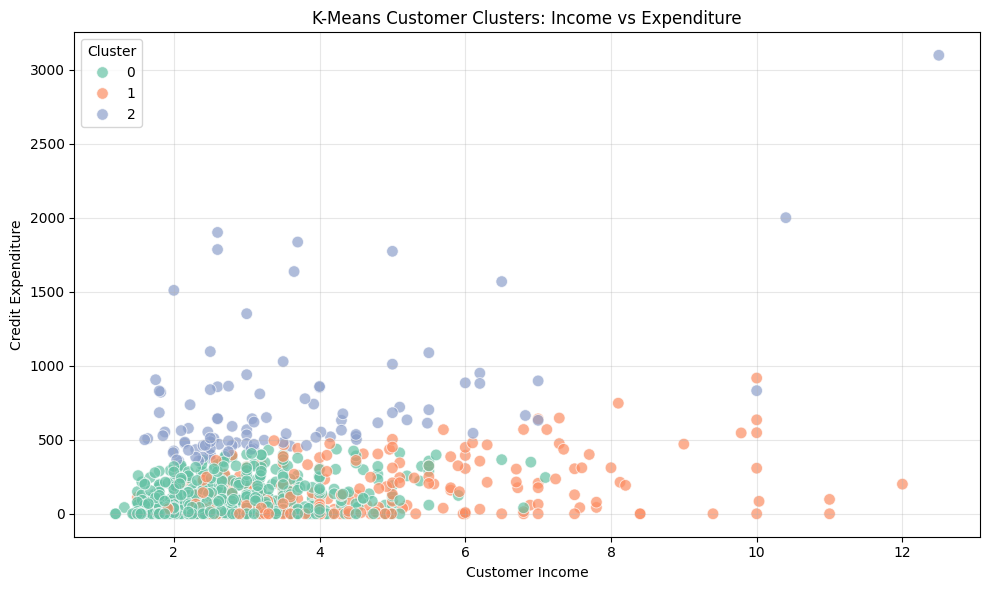

Average Customer Characteristics by Cluster:


,income,expenditure,reports,active,share
Cluster,,,,,
0,2.81,106.17,0.18,4.06,0.05
1,4.53,151.37,1.30,14.12,0.04
2,3.58,727.50,0.11,6.45,0.27



K-Means Model Performance:
Training Silhouette Score: 0.3365
Testing Silhouette Score: 0.3233
Training Inertia: 2933.8764

Number of Customers in Each Cluster:
Cluster
0    579
1    242
2    102
Name: count, dtype: int64


In [19]:
# Step 9: Visualize and Interpret K-Means Clusters

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from IPython.display import display, Markdown

display(Markdown("### Step 9: K-Means Clustering Visualization"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Create a copy of the training data with cluster labels
cluster_results = X_train_cluster.copy()
cluster_results['Cluster'] = train_cluster_labels

# Create a scatter plot of income vs expenditure
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_results,
    x='income',
    y='expenditure',
    hue='Cluster',
    palette='Set2',
    s=70,
    alpha=0.7
)

plt.title('K-Means Customer Clusters: Income vs Expenditure')
plt.xlabel('Customer Income')
plt.ylabel('Credit Expenditure')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate average values for each cluster
cluster_summary = cluster_results.groupby('Cluster')[
    cluster_features
].mean()

# Display cluster characteristics
print("Average Customer Characteristics by Cluster:")
display(cluster_summary.round(2))

# Display model evaluation metrics
print("\nK-Means Model Performance:")
print(f"Training Silhouette Score: {train_silhouette:.4f}")
print(f"Testing Silhouette Score: {test_silhouette:.4f}")
print(f"Training Inertia: {cluster_inertia:.4f}")

# Display cluster sizes
print("\nNumber of Customers in Each Cluster:")
print(cluster_results['Cluster'].value_counts().sort_index())


# Step 10: K-Means Clustering Model Analysis

from IPython.display import display, Markdown

# Find the cluster with the highest and lowest spending
highest_cluster = cluster_summary['expenditure'].idxmax()
lowest_cluster = cluster_summary['expenditure'].idxmin()

highest_spending = cluster_summary.loc[
    highest_cluster, 'expenditure'
]

lowest_spending = cluster_summary.loc[
    lowest_cluster, 'expenditure'
]

# Interpret the silhouette score
if test_silhouette >= 0.5:
    performance = "fairly well separated"
elif test_silhouette >= 0.25:
    performance = "somewhat separated, with some overlap"
else:
    performance = "not clearly separated, with considerable overlap"

# Create the analysis using actual results
analysis_cluster = f"""
### Step 10: K-Means Clustering Model Analysis

Date: {todays_date}

Student ID: {student_id}

**Algorithm Selected: K-Means Clustering**

I chose K-Means because I wanted to see if customers
could be grouped based on similarities in their spending
and credit activity. Since I did not have existing
customer group labels, clustering seemed like a good
way to explore patterns in the dataset.

**Initial Hyperparameters**

I started with n_clusters=3 to explore three possible
customer groups. I used k-means++ to help choose better
starting cluster centers and n_init=10 to run the
algorithm with multiple starting points. I also used
random_state=42 to make the results reproducible.

I standardized the numerical features because K-Means
uses distances, and I did not want features with larger
values to have too much influence.

**Model Performance**

Training Silhouette Score: {train_silhouette:.4f}

Testing Silhouette Score: {test_silhouette:.4f}

Training Inertia: {cluster_inertia:.4f}

**Findings**

The K-Means model divided the customers into three
groups based on income, expenditure, reports, active
accounts, and spending share.

The testing silhouette score was {test_silhouette:.4f},
which suggests the groups were {performance}.

Cluster {highest_cluster} had the highest average credit
expenditure at {highest_spending:.2f}, while Cluster
{lowest_cluster} had the lowest average expenditure
at {lowest_spending:.2f}.

The inertia was {cluster_inertia:.4f}, which measures
how closely the training observations were grouped
around their cluster centers. Lower inertia can
indicate tighter clusters, but it is most useful
when comparing models trained with different
numbers of clusters on the same data.

Overall, the model helped me identify differences
in customer spending patterns. I could improve
the analysis by testing other numbers of clusters
and comparing their silhouette scores.
"""

display(Markdown(analysis_cluster))


In [20]:

# Check that the Credit Card dataset is uploaded

import pandas as pd
import os

print("Files available in Colab:")
print(os.listdir('/content'))

# Load the dataset
df = pd.read_csv('/content/Credit_card_data (1).csv')

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Files available in Colab:
['.config', 'drive', 'Credit_card_data (1).csv', 'sample_data']

Dataset loaded successfully!
Dataset shape: (1319, 12)


,card,reports,age,income,share,expenditure,owner,selfemp,dependents,months,majorcards,active
0,yes,0.0,37.66667,4.5200,0.033270,124.983300,yes,no,3.0,54,1,12.0
1,yes,0.0,33.25000,2.4200,0.005217,9.854167,no,no,3.0,34,1,13.0
2,yes,0.0,33.66667,4.5000,0.004156,15.000000,yes,no,4.0,58,1,5.0
3,yes,0.0,30.50000,2.5400,0.065214,137.869200,no,no,0.0,25,1,7.0
4,yes,0.0,32.16667,9.7867,0.067051,546.503300,yes,no,2.0,64,1,5.0


In [21]:

# Part 4 - Step 2: Classification Model Optimization

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, log_loss
from datetime import datetime
from IPython.display import display, Markdown
import numpy as np

display(Markdown("### Part 4: Classification Optimization"))
display(Markdown(f"Date: {datetime.now().strftime('%Y-%m-%d')}"))
display(Markdown("Student ID: KriAgu7298"))

# Build a pipeline using the original preprocessing
optimized_class_pipeline = Pipeline(steps=[
    ('preprocessor', class_preprocessor),
    ('classifier', LogisticRegression(
        penalty='l2',
        max_iter=2000,
        solver='lbfgs',
        random_state=42
    ))
])

# Search different L2 regularization strengths
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

# Use 5-fold cross-validation to find the best setting
grid_search_class = GridSearchCV(
    optimized_class_pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Train and tune using training data only
grid_search_class.fit(X_train_class, y_train_class)

# Select the best retrained model
optimized_class_model = grid_search_class.best_estimator_

# Evaluate on the original test set
optimized_class_pred = optimized_class_model.predict(X_test_class)
optimized_class_prob = optimized_class_model.predict_proba(X_test_class)

optimized_class_accuracy = accuracy_score(
    y_test_class, optimized_class_pred
)
optimized_class_f1 = f1_score(
    y_test_class, optimized_class_pred,
    zero_division=0
)
optimized_class_loss = log_loss(
    y_test_class, optimized_class_prob,
    labels=optimized_class_model.classes_
)

# Compare original and optimized performance
original_class_prob = classification_model.predict_proba(X_test_class)
original_class_loss = log_loss(
    y_test_class, original_class_prob,
    labels=classification_model.classes_
)

print("\nBest Hyperparameters:", grid_search_class.best_params_)

print("\nOriginal Model:")
print(f"Accuracy: {class_accuracy:.4f}")
print(f"F1 Score: {class_f1:.4f}")
print(f"Log Loss: {original_class_loss:.4f}")

print("\nOptimized Model:")
print(f"Accuracy: {optimized_class_accuracy:.4f}")
print(f"F1 Score: {optimized_class_f1:.4f}")
print(f"Log Loss: {optimized_class_loss:.4f}")

# Create Markdown analysis using actual results
analysis_class = f"""
### Classification Optimization Results

Date: {datetime.now().strftime('%Y-%m-%d')}

Student ID: KriAgu7298

**Optimization Technique:** GridSearchCV with 5-fold cross-validation.

**Regularization:** L2 regularization.

**Best C Value:** {grid_search_class.best_params_['classifier__C']}

**Original Accuracy:** {class_accuracy:.4f}

**Optimized Accuracy:** {optimized_class_accuracy:.4f}

**Original F1 Score:** {class_f1:.4f}

**Optimized F1 Score:** {optimized_class_f1:.4f}

**Original Log Loss:** {original_class_loss:.4f}

**Optimized Log Loss:** {optimized_class_loss:.4f}

The model was retrained using the best regularization setting.
The results show how the optimized model compares with
the original model on the same test data.
"""

display(Markdown(analysis_class))


### Part 4: Classification Optimization

Date: 2026-11-08

Student ID: KriAgu7298


Best Hyperparameters: {'classifier__C': 0.01}

Original Model:
Accuracy: 0.9315
F1 Score: 0.0000
Log Loss: 0.2447

Optimized Model:
Accuracy: 0.9315
F1 Score: 0.0000
Log Loss: 0.2442



### Classification Optimization Results

Date: 2026-11-08

Student ID: KriAgu7298

**Optimization Technique:** GridSearchCV with 5-fold cross-validation.

**Regularization:** L2 regularization.

**Best C Value:** 0.01

**Original Accuracy:** 0.9315

**Optimized Accuracy:** 0.9315

**Original F1 Score:** 0.0000

**Optimized F1 Score:** 0.0000

**Original Log Loss:** 0.2447

**Optimized Log Loss:** 0.2442

The model was retrained using the best regularization setting.
The results show how the optimized model compares with
the original model on the same test data.


In [22]:

# Part 4 - Step 3: Regression Model Optimization

import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from datetime import datetime
from IPython.display import display, Markdown

display(Markdown("### Part 4: Regression Optimization"))
display(Markdown(f"Date: {datetime.now().strftime('%Y-%m-%d')}"))
display(Markdown("Student ID: KriAgu7298"))

# Build a Ridge Regression pipeline using Part 3 preprocessing
optimized_reg_pipeline = Pipeline(steps=[
    ('preprocessor', reg_preprocessor),
    ('regressor', Ridge(max_iter=5000, solver='lsqr'))
])

# Test different L2 regularization strengths
param_grid_reg = {
    'regressor__alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

# Find the best setting using 5-fold cross-validation
grid_search_reg = GridSearchCV(
    optimized_reg_pipeline,
    param_grid_reg,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Train and tune using the original training data
grid_search_reg.fit(X_train_reg, y_train_reg)

# Get the optimized and retrained model
optimized_reg_model = grid_search_reg.best_estimator_

# Predict using the original test set
optimized_reg_pred = optimized_reg_model.predict(X_test_reg)

# Calculate optimized performance metrics
optimized_reg_mse = mean_squared_error(
    y_test_reg, optimized_reg_pred
)
optimized_reg_rmse = np.sqrt(optimized_reg_mse)
optimized_reg_mae = mean_absolute_error(
    y_test_reg, optimized_reg_pred
)
optimized_reg_r2 = r2_score(
    y_test_reg, optimized_reg_pred
)

# Compare original and optimized performance
print("\nBest Hyperparameters:", grid_search_reg.best_params_)

print("\nOriginal Linear Regression:")
print(f"MSE: {reg_mse:.4f}")
print(f"RMSE: {reg_rmse:.4f}")
print(f"MAE: {reg_mae:.4f}")
print(f"R-squared: {reg_r2:.4f}")

print("\nOptimized Ridge Regression:")
print(f"MSE: {optimized_reg_mse:.4f}")
print(f"RMSE: {optimized_reg_rmse:.4f}")
print(f"MAE: {optimized_reg_mae:.4f}")
print(f"R-squared: {optimized_reg_r2:.4f}")

# Determine whether the optimized model improved
if optimized_reg_rmse < reg_rmse:
    result_reg = "improved"
elif optimized_reg_rmse > reg_rmse:
    result_reg = "declined"
else:
    result_reg = "stayed the same"

# Create Markdown analysis with actual results
analysis_reg_optimized = f"""
### Regression Optimization Results

Date: {datetime.now().strftime('%Y-%m-%d')}

Student ID: KriAgu7298

**Original Model:** Linear Regression

**Optimized Model:** Ridge Regression

**Optimization Technique:** GridSearchCV with 5-fold cross-validation.

**Regularization:** L2 regularization.

**Best Alpha Value:** {grid_search_reg.best_params_['regressor__alpha']}

**Original MSE:** {reg_mse:.4f}

**Optimized MSE:** {optimized_reg_mse:.4f}

**Original RMSE:** {reg_rmse:.4f}

**Optimized RMSE:** {optimized_reg_rmse:.4f}

**Original MAE:** {reg_mae:.4f}

**Optimized MAE:** {optimized_reg_mae:.4f}

**Original R-squared:** {reg_r2:.4f}

**Optimized R-squared:** {optimized_reg_r2:.4f}

**Findings**

The regression model's test RMSE {result_reg} after optimization.
GridSearchCV selected the best L2 regularization strength
using the training data. I then evaluated the optimized
model on the same test set as the original model.

Lower MSE, RMSE, and MAE values indicate fewer prediction
errors, while a higher R-squared indicates a better fit.
"""

display(Markdown(analysis_reg_optimized))


### Part 4: Regression Optimization

Date: 2026-11-08

Student ID: KriAgu7298


Best Hyperparameters: {'regressor__alpha': 10}

Original Linear Regression:
MSE: 63345.9329
RMSE: 251.6862
MAE: 155.2868
R-squared: 0.1699

Optimized Ridge Regression:
MSE: 63274.5964
RMSE: 251.5444
MAE: 154.4997
R-squared: 0.1709



### Regression Optimization Results

Date: 2026-11-08

Student ID: KriAgu7298

**Original Model:** Linear Regression

**Optimized Model:** Ridge Regression

**Optimization Technique:** GridSearchCV with 5-fold cross-validation.

**Regularization:** L2 regularization.

**Best Alpha Value:** 10

**Original MSE:** 63345.9329

**Optimized MSE:** 63274.5964

**Original RMSE:** 251.6862

**Optimized RMSE:** 251.5444

**Original MAE:** 155.2868

**Optimized MAE:** 154.4997

**Original R-squared:** 0.1699

**Optimized R-squared:** 0.1709

**Findings**

The regression model's test RMSE improved after optimization.
GridSearchCV selected the best L2 regularization strength
using the training data. I then evaluated the optimized
model on the same test set as the original model.

Lower MSE, RMSE, and MAE values indicate fewer prediction
errors, while a higher R-squared indicates a better fit.


### Part 4: Clustering Optimization

Date: 2026-11-08

Student ID: KriAgu7298

,n_clusters,n_init,silhouette
0,2,10,0.3610
1,2,20,0.3610
2,3,10,0.3365
3,3,20,0.3365
4,4,10,0.3396
5,4,20,0.3396
6,5,10,0.3248
7,5,20,0.3234
8,6,10,0.3362
9,6,20,0.3362



Best Hyperparameters:
Number of Clusters: 2
Number of Initializations: 10

Original K-Means Model:
Test Silhouette Score: 0.3233
Training Inertia: 2933.8764

Optimized K-Means Model:
Test Silhouette Score: 0.3920
Training Inertia: 3619.3610


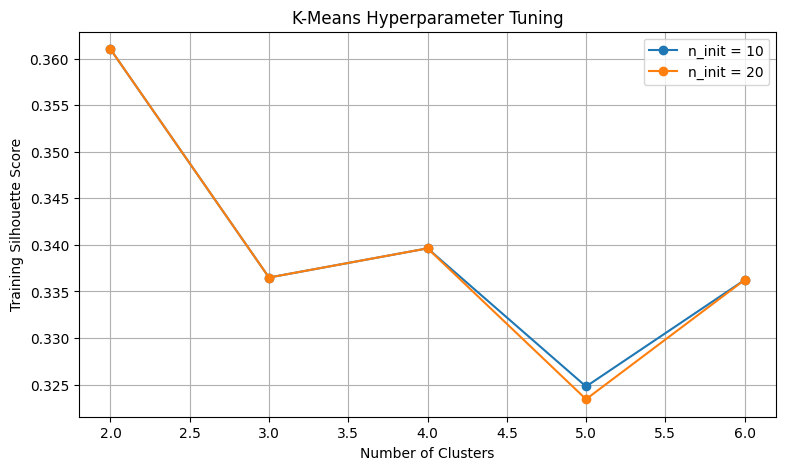


### Clustering Optimization Results

Date: 2026-11-08

Student ID: KriAgu7298

**Original Model:** K-Means with 3 clusters

**Optimization Technique:** Parameter grid search using training silhouette scores.

**Regularization / Stability Technique:** Multiple K-Means initializations using n_init.

**Best Number of Clusters:** 2

**Best Number of Initializations:** 10

**Original Test Silhouette Score:** 0.3233

**Optimized Test Silhouette Score:** 0.3920

**Original Training Inertia:** 2933.8764

**Optimized Training Inertia:** 3619.3610

**Findings**

The clustering model's test silhouette score improved
after optimization. I tested different numbers of clusters
and initialization settings, then retrained K-Means using
the best combination.

Multiple initializations help reduce sensitivity to the
starting cluster centers. The silhouette score measures
how well separated the customer groups are. Higher
silhouette scores generally indicate better separation.

K-Means does not use classification accuracy or a
supervised loss function. I used silhouette score and
inertia to evaluate its performance instead.


In [23]:

# Part 4 - Step 4: K-Means Clustering Optimization

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import pairwise_distances_argmin
from datetime import datetime
from IPython.display import display, Markdown

display(Markdown("### Part 4: Clustering Optimization"))
display(Markdown(f"Date: {datetime.now().strftime('%Y-%m-%d')}"))
display(Markdown("Student ID: KriAgu7298"))

# Use the same scaled training and testing data from Part 3
# Search different cluster counts and initialization settings
param_grid_cluster = {
    'n_clusters': [2, 3, 4, 5, 6],
    'n_init': [10, 20]
}

results_cluster = []

# Search for the best parameters using training data only
for params in ParameterGrid(param_grid_cluster):
    candidate = KMeans(
        n_clusters=params['n_clusters'],
        n_init=params['n_init'],
        init='k-means++',
        random_state=42
    )

    labels = candidate.fit_predict(X_train_cluster_scaled)

    score = silhouette_score(
        X_train_cluster_scaled, labels
    )

    results_cluster.append({
        'n_clusters': params['n_clusters'],
        'n_init': params['n_init'],
        'silhouette': score
    })

# Display parameter search results
cluster_search_results = pd.DataFrame(results_cluster)
display(cluster_search_results.round(4))

# Find the best settings
best_cluster_row = cluster_search_results.loc[
    cluster_search_results['silhouette'].idxmax()
]

best_n_clusters = int(best_cluster_row['n_clusters'])
best_n_init = int(best_cluster_row['n_init'])

# Retrain the optimized model
optimized_kmeans = KMeans(
    n_clusters=best_n_clusters,
    n_init=best_n_init,
    init='k-means++',
    random_state=42
)

optimized_kmeans.fit(X_train_cluster_scaled)

# Evaluate the optimized model on the test set
optimized_test_labels = optimized_kmeans.predict(
    X_test_cluster_scaled
)

optimized_train_silhouette = silhouette_score(
    X_train_cluster_scaled,
    optimized_kmeans.labels_
)

optimized_test_silhouette = silhouette_score(
    X_test_cluster_scaled,
    optimized_test_labels
)

optimized_inertia = optimized_kmeans.inertia_

# Compare original and optimized performance
print("\nBest Hyperparameters:")
print("Number of Clusters:", best_n_clusters)
print("Number of Initializations:", best_n_init)

print("\nOriginal K-Means Model:")
print(f"Test Silhouette Score: {test_silhouette:.4f}")
print(f"Training Inertia: {cluster_inertia:.4f}")

print("\nOptimized K-Means Model:")
print(f"Test Silhouette Score: {optimized_test_silhouette:.4f}")
print(f"Training Inertia: {optimized_inertia:.4f}")

# Compare performance based on test silhouette
if optimized_test_silhouette > test_silhouette:
    cluster_result = "improved"
elif optimized_test_silhouette < test_silhouette:
    cluster_result = "declined"
else:
    cluster_result = "stayed the same"

# Visualize silhouette scores from the parameter search
plt.figure(figsize=(9, 5))

for n_init_value in [10, 20]:
    subset = cluster_search_results[
        cluster_search_results['n_init'] == n_init_value
    ]
    plt.plot(
        subset['n_clusters'],
        subset['silhouette'],
        marker='o',
        label=f"n_init = {n_init_value}"
    )

plt.title("K-Means Hyperparameter Tuning")
plt.xlabel("Number of Clusters")
plt.ylabel("Training Silhouette Score")
plt.legend()
plt.grid(True)
plt.show()

# Display Markdown analysis with actual results
analysis_cluster_optimized = f"""
### Clustering Optimization Results

Date: {datetime.now().strftime('%Y-%m-%d')}

Student ID: KriAgu7298

**Original Model:** K-Means with 3 clusters

**Optimization Technique:** Parameter grid search using training silhouette scores.

**Regularization / Stability Technique:** Multiple K-Means initializations using n_init.

**Best Number of Clusters:** {best_n_clusters}

**Best Number of Initializations:** {best_n_init}

**Original Test Silhouette Score:** {test_silhouette:.4f}

**Optimized Test Silhouette Score:** {optimized_test_silhouette:.4f}

**Original Training Inertia:** {cluster_inertia:.4f}

**Optimized Training Inertia:** {optimized_inertia:.4f}

**Findings**

The clustering model's test silhouette score {cluster_result}
after optimization. I tested different numbers of clusters
and initialization settings, then retrained K-Means using
the best combination.

Multiple initializations help reduce sensitivity to the
starting cluster centers. The silhouette score measures
how well separated the customer groups are. Higher
silhouette scores generally indicate better separation.

K-Means does not use classification accuracy or a
supervised loss function. I used silhouette score and
inertia to evaluate its performance instead.
"""

display(Markdown(analysis_cluster_optimized))



# Final Project: Scenario and Impact Analysis

Date: 2026-11-08

Student ID: KriAgu7298

## Project Overview

This project continues my analysis of the Credit Card dataset from Parts 3 and 4. I will use my optimized Ridge Regression model to test how changes in customer characteristics affect predicted credit expenditure. I will compare three different scenarios with the original predictions and perform sensitivity analysis to see which changes have the greatest impact.



## Step 3: Scenario Development

Date: 2026-11-08

Student ID: KriAgu7298

### Scenario 1: Increased Customer Income

In this scenario, customer income increases by 20% while other characteristics stay the same. This could represent customers receiving raises or experiencing better economic conditions. I want to see whether higher income leads to higher predicted credit expenditure.

### Scenario 2: Decreased Customer Income

In this scenario, customer income decreases by 20% while other characteristics stay the same. This could represent job changes, reduced working hours, or financial difficulties. Testing this scenario can help show how lower income might affect predicted customer spending.

### Scenario 3: Increased Credit Activity

In this scenario, the number of active credit accounts increases by one for each customer while other characteristics stay the same. This could represent customers opening additional credit accounts. I want to see whether increased credit activity changes predicted expenditure.


In [24]:

# Step 4: Scenario Simulation

from datetime import datetime
todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "KriAgu7298"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

display(Markdown("### Step 4: Scenario Simulation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Use the optimized Ridge Regression model from Part 4
model = optimized_reg_model

# Calculate baseline predictions
baseline_predictions = model.predict(X_test_reg)
baseline_average = np.mean(baseline_predictions)

# Scenario 1: Increase customer income by 20%
scenario_1 = X_test_reg.copy()
scenario_1["income"] = scenario_1["income"] * 1.20
scenario_1_predictions = model.predict(scenario_1)

# Scenario 2: Decrease customer income by 20%
scenario_2 = X_test_reg.copy()
scenario_2["income"] = scenario_2["income"] * 0.80
scenario_2_predictions = model.predict(scenario_2)

# Scenario 3: Increase active credit accounts by one
scenario_3 = X_test_reg.copy()
scenario_3["active"] = scenario_3["active"].fillna(
    X_train_reg["active"].median()
) + 1
scenario_3_predictions = model.predict(scenario_3)

# Create comparison table
scenario_results = pd.DataFrame({
    "Scenario": [
        "Baseline",
        "Income +20%",
        "Income -20%",
        "Active Accounts +1"
    ],
    "Average Predicted Expenditure": [
        baseline_average,
        np.mean(scenario_1_predictions),
        np.mean(scenario_2_predictions),
        np.mean(scenario_3_predictions)
    ]
})

# Calculate changes compared to baseline
scenario_results["Change from Baseline"] = (
    scenario_results["Average Predicted Expenditure"]
    - baseline_average
)

# Display results
display(scenario_results.round(2))


### Step 4: Scenario Simulation

Date: 2026-11-08

Student ID: KriAgu7298

,Scenario,Average Predicted Expenditure,Change from Baseline
0,Baseline,186.95,0.00
1,Income +20%,220.51,33.56
2,Income -20%,153.39,-33.56
3,Active Accounts +1,185.86,-1.08


### Step 5: Scenario Comparison Visualization

Date: 2026-11-08

Student ID: KriAgu7298

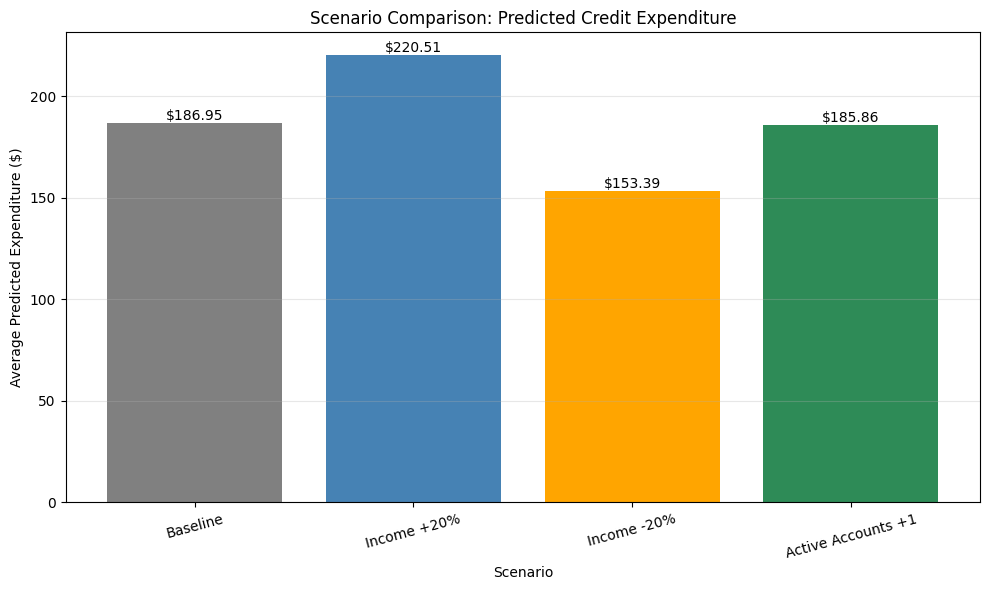

### Changes Compared to Baseline

,Scenario,Change from Baseline
0,Baseline,0.00
1,Income +20%,33.56
2,Income -20%,-33.56
3,Active Accounts +1,-1.08


In [25]:

# Step 5: Scenario Comparison Visualization

import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import display, Markdown

display(Markdown("### Step 5: Scenario Comparison Visualization"))
display(Markdown(f"Date: {datetime.now().strftime('%Y-%m-%d')}"))
display(Markdown("Student ID: KriAgu7298"))

# Use the results calculated in Step 4
labels = scenario_results["Scenario"]
values = scenario_results["Average Predicted Expenditure"]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    labels,
    values,
    color=["gray", "steelblue", "orange", "seagreen"]
)

# Display predicted values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:.2f}",
        ha="center",
        va="bottom"
    )

plt.title("Scenario Comparison: Predicted Credit Expenditure")
plt.xlabel("Scenario")
plt.ylabel("Average Predicted Expenditure ($)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display changes compared with baseline
display(Markdown("### Changes Compared to Baseline"))
display(
    scenario_results[
        ["Scenario", "Change from Baseline"]
    ].round(2)
)


### Step 6: Sensitivity and Impact Analysis

Date: 2026-11-08

Student ID: KriAgu7298

#### Income Sensitivity Results

,Income Change (%),Predicted Expenditure
0,-20,153.39
1,-10,170.17
2,0,186.95
3,10,203.73
4,20,220.51


#### Active Account Sensitivity Results

,Active Account Change,Predicted Expenditure
0,-1,187.86
1,0,186.95
2,1,185.87
3,2,184.79


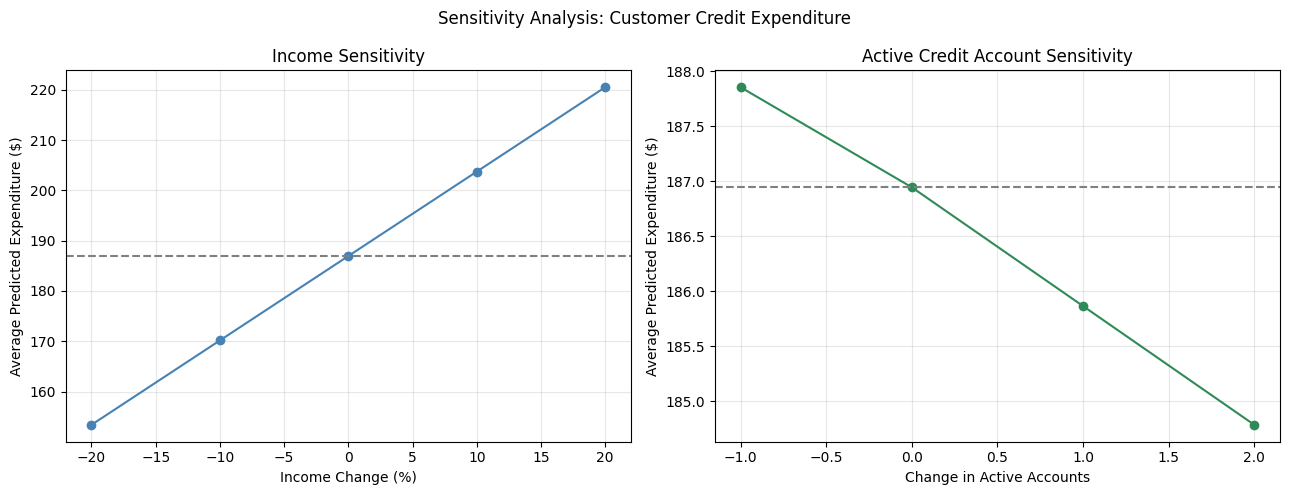

In [26]:

# Step 6: Sensitivity and Impact Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import display, Markdown

display(Markdown("### Step 6: Sensitivity and Impact Analysis"))
display(Markdown(f"Date: {datetime.now().strftime('%Y-%m-%d')}"))
display(Markdown("Student ID: KriAgu7298"))

# Use the optimized model and original testing data
model = optimized_reg_model
baseline_data = X_test_reg.copy()
baseline_avg = np.mean(model.predict(baseline_data))

# Test different income changes
income_changes = [-20, -10, 0, 10, 20]
income_predictions = []

for change in income_changes:
    test_data = baseline_data.copy()
    test_data["income"] = test_data["income"] * (1 + change / 100)
    income_predictions.append(np.mean(model.predict(test_data)))

# Test changes in active credit accounts
active_changes = [-1, 0, 1, 2]
active_predictions = []

for change in active_changes:
    test_data = baseline_data.copy()
    test_data["active"] = (
        test_data["active"] + change
    ).clip(lower=0)
    active_predictions.append(np.mean(model.predict(test_data)))

# Create sensitivity results table
income_results = pd.DataFrame({
    "Income Change (%)": income_changes,
    "Predicted Expenditure": income_predictions
})

active_results = pd.DataFrame({
    "Active Account Change": active_changes,
    "Predicted Expenditure": active_predictions
})

display(Markdown("#### Income Sensitivity Results"))
display(income_results.round(2))

display(Markdown("#### Active Account Sensitivity Results"))
display(active_results.round(2))

# Plot sensitivity results
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    income_changes, income_predictions,
    marker="o", color="steelblue"
)
axes[0].axhline(baseline_avg, linestyle="--", color="gray")
axes[0].set_title("Income Sensitivity")
axes[0].set_xlabel("Income Change (%)")
axes[0].set_ylabel("Average Predicted Expenditure ($)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    active_changes, active_predictions,
    marker="o", color="seagreen"
)
axes[1].axhline(baseline_avg, linestyle="--", color="gray")
axes[1].set_title("Active Credit Account Sensitivity")
axes[1].set_xlabel("Change in Active Accounts")
axes[1].set_ylabel("Average Predicted Expenditure ($)")
axes[1].grid(alpha=0.3)

plt.suptitle("Sensitivity Analysis: Customer Credit Expenditure")
plt.tight_layout()
plt.show()



## Step 7: Sensitivity Analysis and Business Implications

Date: 2026-11-08

Student ID: KriAgu7298

### Sensitivity Analysis

For this analysis, I tested two features from my Credit Card dataset: customer income and the number of active credit accounts. I changed income between -20% and +20% and adjusted active credit accounts between -1 and +2. I kept the other features the same so I could see how each change affected the model's predictions.

The results show how sensitive the Ridge Regression model is to these two features. Comparing the predicted expenditure values with the baseline helps identify which changes have a larger effect on the model's output.

### Business Implications

This analysis could help businesses understand possible changes in customer spending. For example, retailers could use spending predictions to help plan promotions, customer rewards, and inventory. Understanding how income and credit activity relate to predicted expenditure could also help businesses identify different customer spending patterns.

### Limitations

These scenarios are hypothetical and do not prove that changing income or credit accounts directly causes spending to change. My optimized Ridge Regression model also had a relatively low R-squared value, so its predictions have limitations. Other factors that were not included in the dataset may also affect customer expenditure.



## Step 8: Final Findings and Recommendations

Date: 2026-11-08

Student ID: KriAgu7298

### Final Findings

For my Credit Card dataset project, I completed classification, regression, and clustering tasks. I used Logistic Regression to predict self-employment status, Ridge Regression to predict credit expenditure, and K-Means to group customers based on their characteristics.

The optimized classification model had 93.15% accuracy, but its F1 score was 0 because it did not correctly identify self-employed customers. My optimized Ridge Regression model had an RMSE of 251.54 and an R-squared value of 0.1709, which shows that it could only explain a small portion of spending differences. My optimized K-Means model improved its silhouette score to 0.3920.

For the scenario analysis, I tested increases and decreases in customer income and an increase in active credit accounts. I compared the predicted spending results with the baseline and then tested different changes in income and credit activity to see how sensitive the model was.

### Recommendations

Businesses could use this type of analysis to explore customer spending patterns and help plan promotions, loyalty programs, and inventory. However, the results should be used carefully because the models have limitations.

I would recommend collecting more customer information, testing additional features, and improving the models before using these predictions for important business decisions.

### Final Reflection

This project helped me understand how classification, regression, and clustering can answer different business questions. I also learned that optimizing a model does not always make it accurate enough for real-world decisions. Scenario testing and sensitivity analysis helped me see how changing input features can affect predictions and why it is important to understand a model's limitations.
